# Lab 3 - Construire une stratégie complète de risque IA

**Scénario.** SmartHire est un outil fictif de présélection de CV. Il présente un écart de classement selon le genre, une faible explicabilité et l'absence de journalisation et de suivi.

**Objectif.** Produire une stratégie structurée sur quatre domaines, l'exporter en YAML et vérifier que la documentation et la visualisation sont bien créées.

## Comment utiliser ce notebook

Une stratégie de risque n'est pas une liste figée : elle relie un scénario, des contrôles, des responsables et des preuves. Ici, le notebook montre comment structurer et partager cette liste. Exécutez les cellules dans l'ordre : la stratégie est définie, validée, exportée, relue, puis représentée graphiquement. Les cellules **Test** confirment que chaque étape a produit le résultat attendu.

In [1]:
from pathlib import Path
from datetime import date
import yaml
import matplotlib.pyplot as plt

PROJECT_ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "requirements.txt").exists()), Path.cwd())
ARTIFACTS = PROJECT_ROOT / "notebooks" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

## 1. Formaliser le périmètre et les contrôles

Les contrôles sont rangés par domaine pour éviter de réduire le risque IA à un problème purement technique. Cette liste est un point de départ : chaque contrôle doit recevoir un responsable, une date, un critère d'acceptation et une preuve.

**Lecture de la structure :** le dictionnaire utilise un domaine comme clé et une liste de contrôles comme valeur. `Technique` couvre le comportement du modèle ; `Opérationnel` son fonctionnement dans le temps ; `Éthique` les effets sur les personnes ; `Juridique` les obligations applicables. La boucle finale affiche ces éléments pour que la stratégie reste lisible avant tout export. Le test impose quatre domaines et au moins trois contrôles non vides dans chacun : c'est un contrôle de complétude minimale.

In [2]:
risk_strategy = {
    "Technique": ["Mesurer les écarts d'équité avant chaque version", "Surveiller dérive et performance après déploiement", "Fournir des raisons de classement compréhensibles"],
    "Opérationnel": ["Versionner modèle, données et paramètres", "Conserver la lignée des données et les changements", "Tester un plan de réponse aux incidents IA"],
    "Éthique": ["Auditer les biais sur des populations pertinentes", "Définir des critères d'équité avec les parties prenantes", "Prévoir une revue humaine et une voie de recours"],
    "Juridique": ["Documenter la base légale et le consentement applicable", "Évaluer les décisions automatisées à effet significatif", "Valider les obligations de transparence et de non-discrimination"],
}
for domain, controls in risk_strategy.items():
    print(f"\n{domain.upper()} ({len(controls)} contrôles)")
    for control in controls:
        print(f"- {control}")


TECHNIQUE (3 contrôles)
- Mesurer les écarts d'équité avant chaque version
- Surveiller dérive et performance après déploiement
- Fournir des raisons de classement compréhensibles

OPÉRATIONNEL (3 contrôles)
- Versionner modèle, données et paramètres
- Conserver la lignée des données et les changements
- Tester un plan de réponse aux incidents IA

ÉTHIQUE (3 contrôles)
- Auditer les biais sur des populations pertinentes
- Définir des critères d'équité avec les parties prenantes
- Prévoir une revue humaine et une voie de recours

JURIDIQUE (3 contrôles)
- Documenter la base légale et le consentement applicable
- Évaluer les décisions automatisées à effet significatif
- Valider les obligations de transparence et de non-discrimination


In [3]:
# Test - stratégie équilibrée : quatre domaines, trois contrôles non vides dans chacun.
assert set(risk_strategy) == {"Technique", "Opérationnel", "Éthique", "Juridique"}
assert all(len(controls) >= 3 and all(isinstance(c, str) and c for c in controls) for controls in risk_strategy.values())
print("OK - stratégie structurée et complète.")

OK - stratégie structurée et complète.


## 2. Exporter une documentation YAML

YAML est lisible par une personne et exploitable par un outil. `safe_dump` empêche l'émission de types Python spécifiques ; `allow_unicode=True` conserve les accents français. La relecture après écriture est un test crucial : elle vérifie l'artefact réellement livré, pas seulement l'objet en mémoire.

**Déroulé :** `document` sépare les métadonnées de la stratégie métier ; `safe_dump` convertit ce dictionnaire en YAML ; `write_text` enregistre le fichier ; la cellule de test charge de nouveau le fichier avec `safe_load` et compare la stratégie relue à celle créée en mémoire. Si les deux diffèrent, l'exécution s'arrête : cela détecte un problème de sérialisation ou de chemin de fichier.

In [4]:
document = {
    "metadata": {
        "projet": "SmartHire - stratégie de risque IA",
        "date_generation": date.today().isoformat(),
        "statut": "Brouillon à valider",
        "scenario": "Écart de classement, explicabilité insuffisante et absence de surveillance.",
    },
    "strategie_risque": risk_strategy,
}
yaml_path = ARTIFACTS / "lab3_strategie_risque.yaml"
yaml_path.write_text(yaml.safe_dump(document, allow_unicode=True, sort_keys=False), encoding="utf-8")
print(yaml_path.read_text(encoding="utf-8"))

metadata:
  projet: SmartHire - stratégie de risque IA
  date_generation: '2026-11-02'
  statut: Brouillon à valider
  scenario: Écart de classement, explicabilité insuffisante et absence de surveillance.
strategie_risque:
  Technique:
  - Mesurer les écarts d'équité avant chaque version
  - Surveiller dérive et performance après déploiement
  - Fournir des raisons de classement compréhensibles
  Opérationnel:
  - Versionner modèle, données et paramètres
  - Conserver la lignée des données et les changements
  - Tester un plan de réponse aux incidents IA
  Éthique:
  - Auditer les biais sur des populations pertinentes
  - Définir des critères d'équité avec les parties prenantes
  - Prévoir une revue humaine et une voie de recours
  Juridique:
  - Documenter la base légale et le consentement applicable
  - Évaluer les décisions automatisées à effet significatif
  - Valider les obligations de transparence et de non-discrimination



In [5]:
# Test - relecture YAML et égalité du contenu métier.
loaded = yaml.safe_load(yaml_path.read_text(encoding="utf-8"))
assert loaded["strategie_risque"] == risk_strategy
assert loaded["metadata"]["projet"].startswith("SmartHire")
assert yaml_path.exists()
print("OK - export YAML relu et validé.")

OK - export YAML relu et validé.


## 3. Visualiser la couverture des contrôles

Le graphique compte les contrôles, il ne mesure pas leur efficacité. Un domaine avec davantage de contrôles n'est pas nécessairement mieux couvert ; la qualité des preuves et l'efficacité observée restent déterminantes.

**Comment le graphique est construit :** `domains` conserve l'ordre des domaines, `counts` calcule la taille de chaque liste, `bar` trace une barre par domaine et la boucle ajoute le chiffre au-dessus de chaque barre. `savefig` produit une image réutilisable dans un rapport. Le test compare les comptes affichés aux listes d'origine et s'assure que l'image existe et n'est pas vide. Interprétez ensuite les écarts : un faible nombre de contrôles peut signaler une lacune ou, au contraire, des contrôles plus larges - il faut examiner leur efficacité.

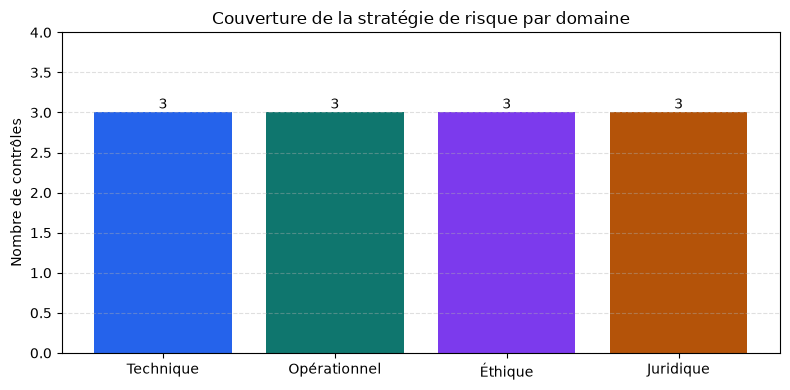

In [6]:
domains = list(risk_strategy)
counts = [len(risk_strategy[d]) for d in domains]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(domains, counts, color=["#2563eb", "#0f766e", "#7c3aed", "#b45309"])
ax.set_title("Couverture de la stratégie de risque par domaine")
ax.set_ylabel("Nombre de contrôles")
ax.set_ylim(0, max(counts) + 1)
ax.grid(axis="y", linestyle="--", alpha=.4)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, count + .05, str(count), ha="center")
fig.tight_layout()
figure_path = ARTIFACTS / "lab3_couverture_controles.png"
fig.savefig(figure_path, dpi=150)
plt.show()

In [7]:
# Test - les comptes reflètent exactement la stratégie et l'image a été écrite.
assert counts == [len(v) for v in risk_strategy.values()]
assert figure_path.exists() and figure_path.stat().st_size > 1_000
print("OK - visualisation créée et validée.")

OK - visualisation créée et validée.


## Réflexion finale

Quelle preuve demanderiez-vous pour juger qu'un contrôle est efficace ? Pensez aux métriques, aux journaux, aux revues humaines et aux retours des candidats. Une stratégie devient opérationnelle seulement lorsque ses contrôles sont mesurés, suivis et améliorés dans le temps.